# MindScope - Exploratory Data Analysis

In this notebook I explore the student mental health dataset to understand the data before building a model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../data/raw/student_mental_health.csv")
target = "Mental_Health_Risk"

print(df.shape)
df.head()

(2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [3]:
df = df.drop(columns=["Student_ID"])
df.shape

(2000, 16)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2000 non-null   int64  
 1   Gender                          2000 non-null   str    
 2   Year_of_Study                   2000 non-null   int64  
 3   Sleep_Hours                     1938 non-null   float64
 4   Study_Hours_Per_Week            2000 non-null   float64
 5   GPA                             1962 non-null   float64
 6   Social_Media_Hours              1942 non-null   float64
 7   Screen_Time_Hours               2000 non-null   float64
 8   Physical_Activity               2000 non-null   str    
 9   Financial_Stress                1909 non-null   float64
 10  Family_Support                  1946 non-null   float64
 11  Attendance_Rate                 1953 non-null   float64
 12  Part_Time_Job                   2000 non-null

In [5]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

if target in num_cols:
    num_cols.remove(target)
if target in cat_cols:
    cat_cols.remove(target)

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical columns: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


In [6]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [7]:
df[cat_cols].describe()

,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History
count,2000,2000,2000,1931,2000
unique,3,3,2,3,2
top,Female,Moderate,No,Average,No
freq,971,906,1289,860,1408


## Missing values

In [8]:
missing = df.isnull().sum()
print(missing)
print("Total missing values:", missing.sum())

Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64
Total missing values: 419


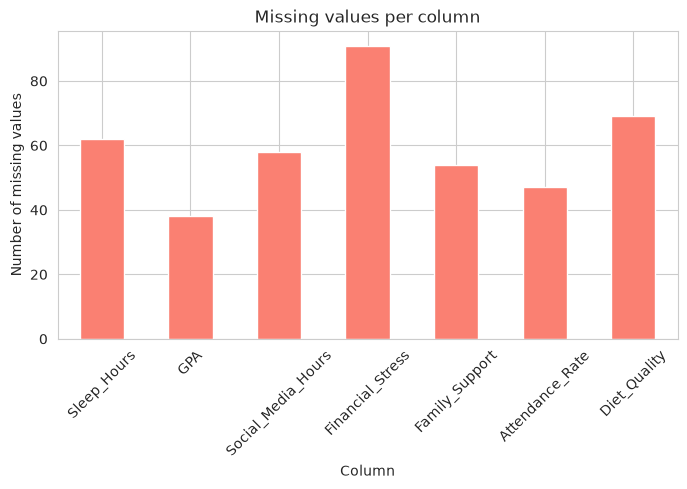

In [9]:
if missing.sum() > 0:
    plt.figure(figsize=(8, 4))
    missing[missing > 0].plot(kind="bar", color="salmon")
    plt.title("Missing values per column")
    plt.xlabel("Column")
    plt.ylabel("Number of missing values")
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No missing values")

## Duplicates

In [10]:
print("Number of duplicated rows:", df.duplicated().sum())

Number of duplicated rows: 0


## Outliers

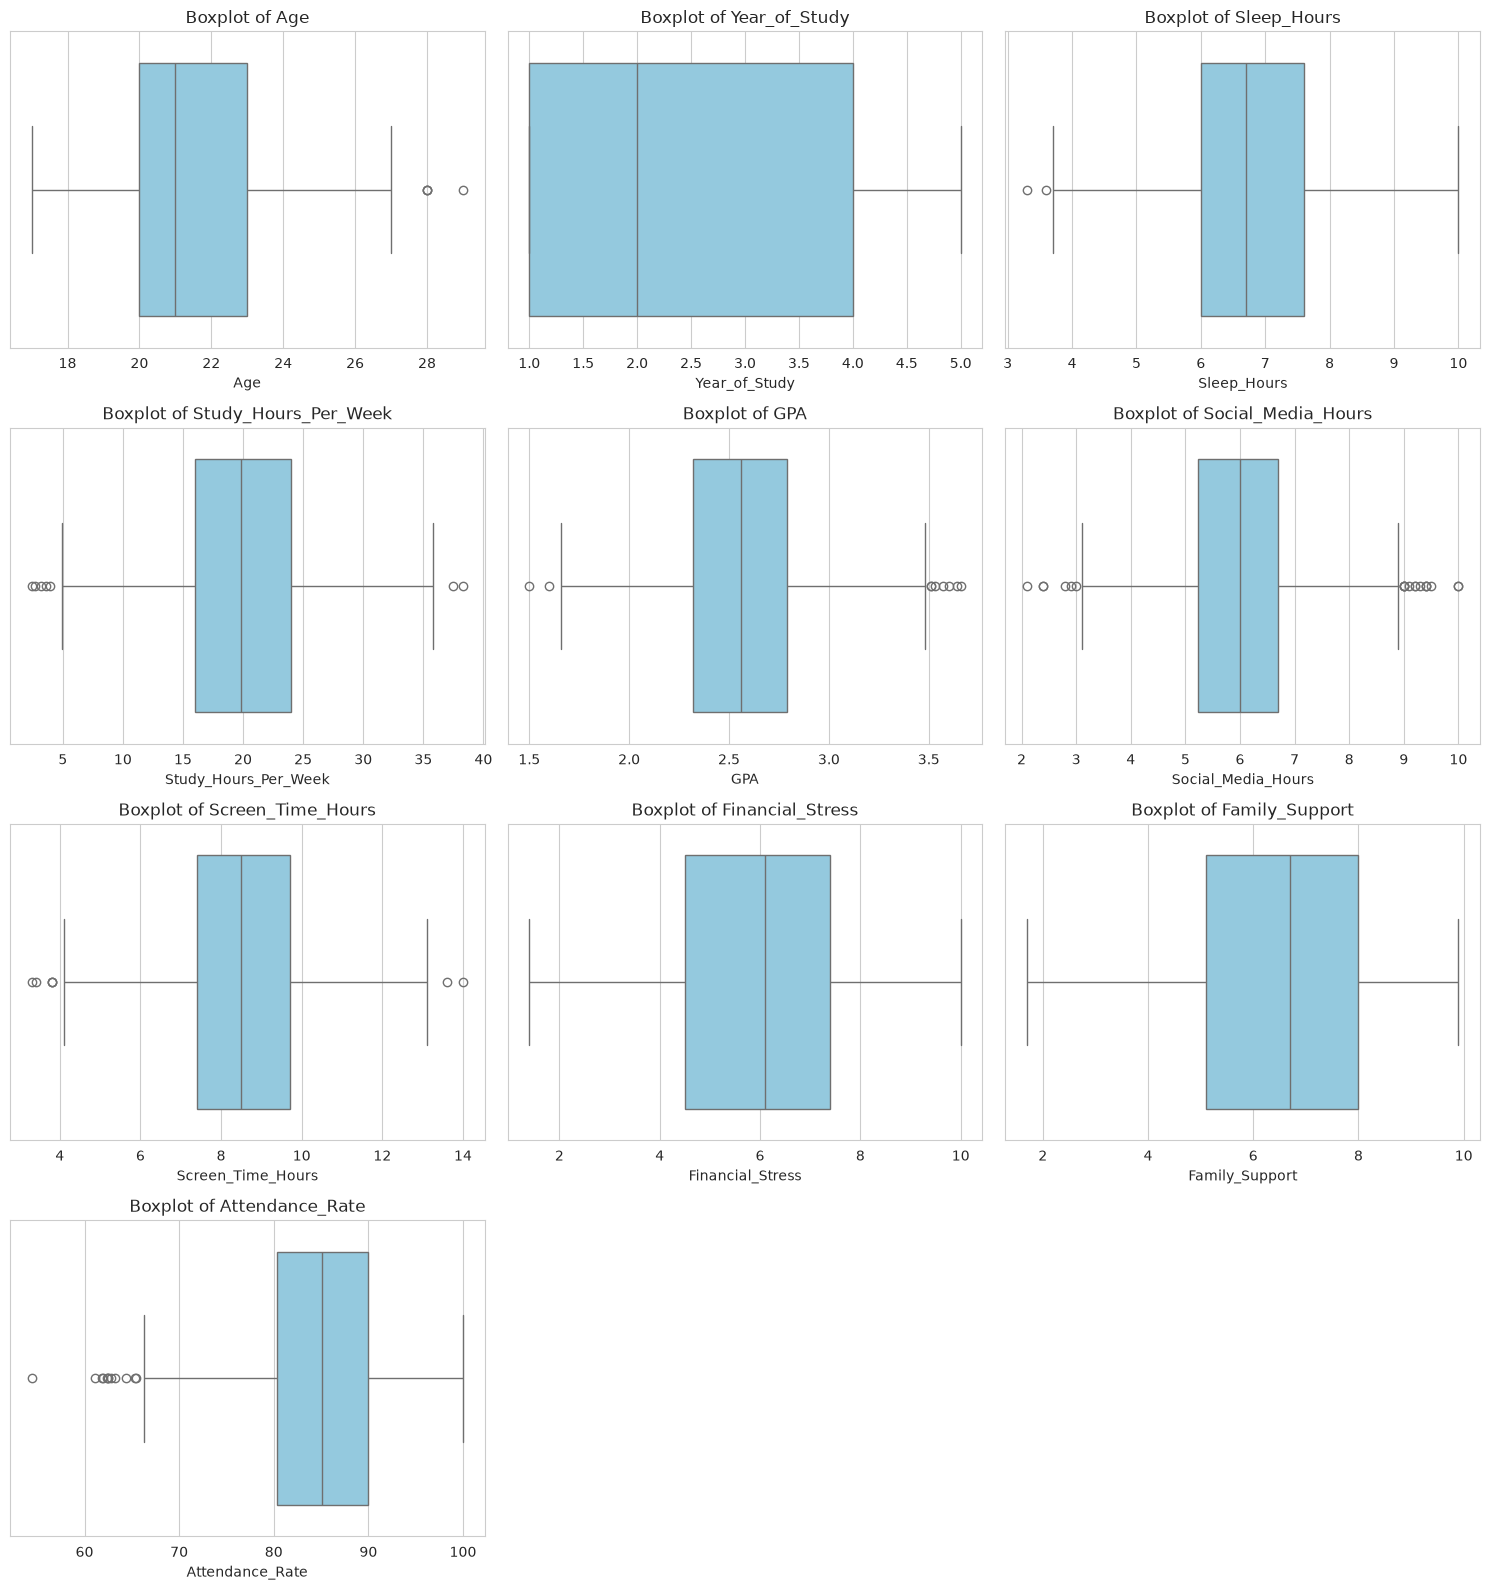

In [11]:
rows = (len(num_cols) + 2) // 3

plt.figure(figsize=(15, 4 * rows))
for i, col in enumerate(num_cols):
    plt.subplot(rows, 3, i + 1)
    sns.boxplot(x=df[col], color="skyblue")
    plt.title("Boxplot of " + col)
plt.tight_layout()
plt.show()

In [12]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_outliers = ((df[col] < low) | (df[col] > high)).sum()
    print(col, ":", n_outliers, "outliers")

Age : 4 outliers
Year_of_Study : 0 outliers
Sleep_Hours : 2 outliers
Study_Hours_Per_Week : 7 outliers
GPA : 9 outliers
Social_Media_Hours : 20 outliers
Screen_Time_Hours : 7 outliers
Financial_Stress : 0 outliers
Family_Support : 0 outliers
Attendance_Rate : 12 outliers


## Target variable

In [13]:
print(df[target].value_counts())
print()
print(df[target].value_counts(normalize=True) * 100)

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


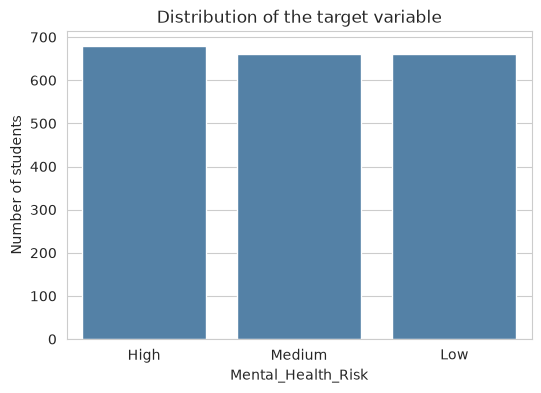

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df[target], color="steelblue")
plt.title("Distribution of the target variable")
plt.xlabel(target)
plt.ylabel("Number of students")
plt.show()

## Distribution of the numerical features

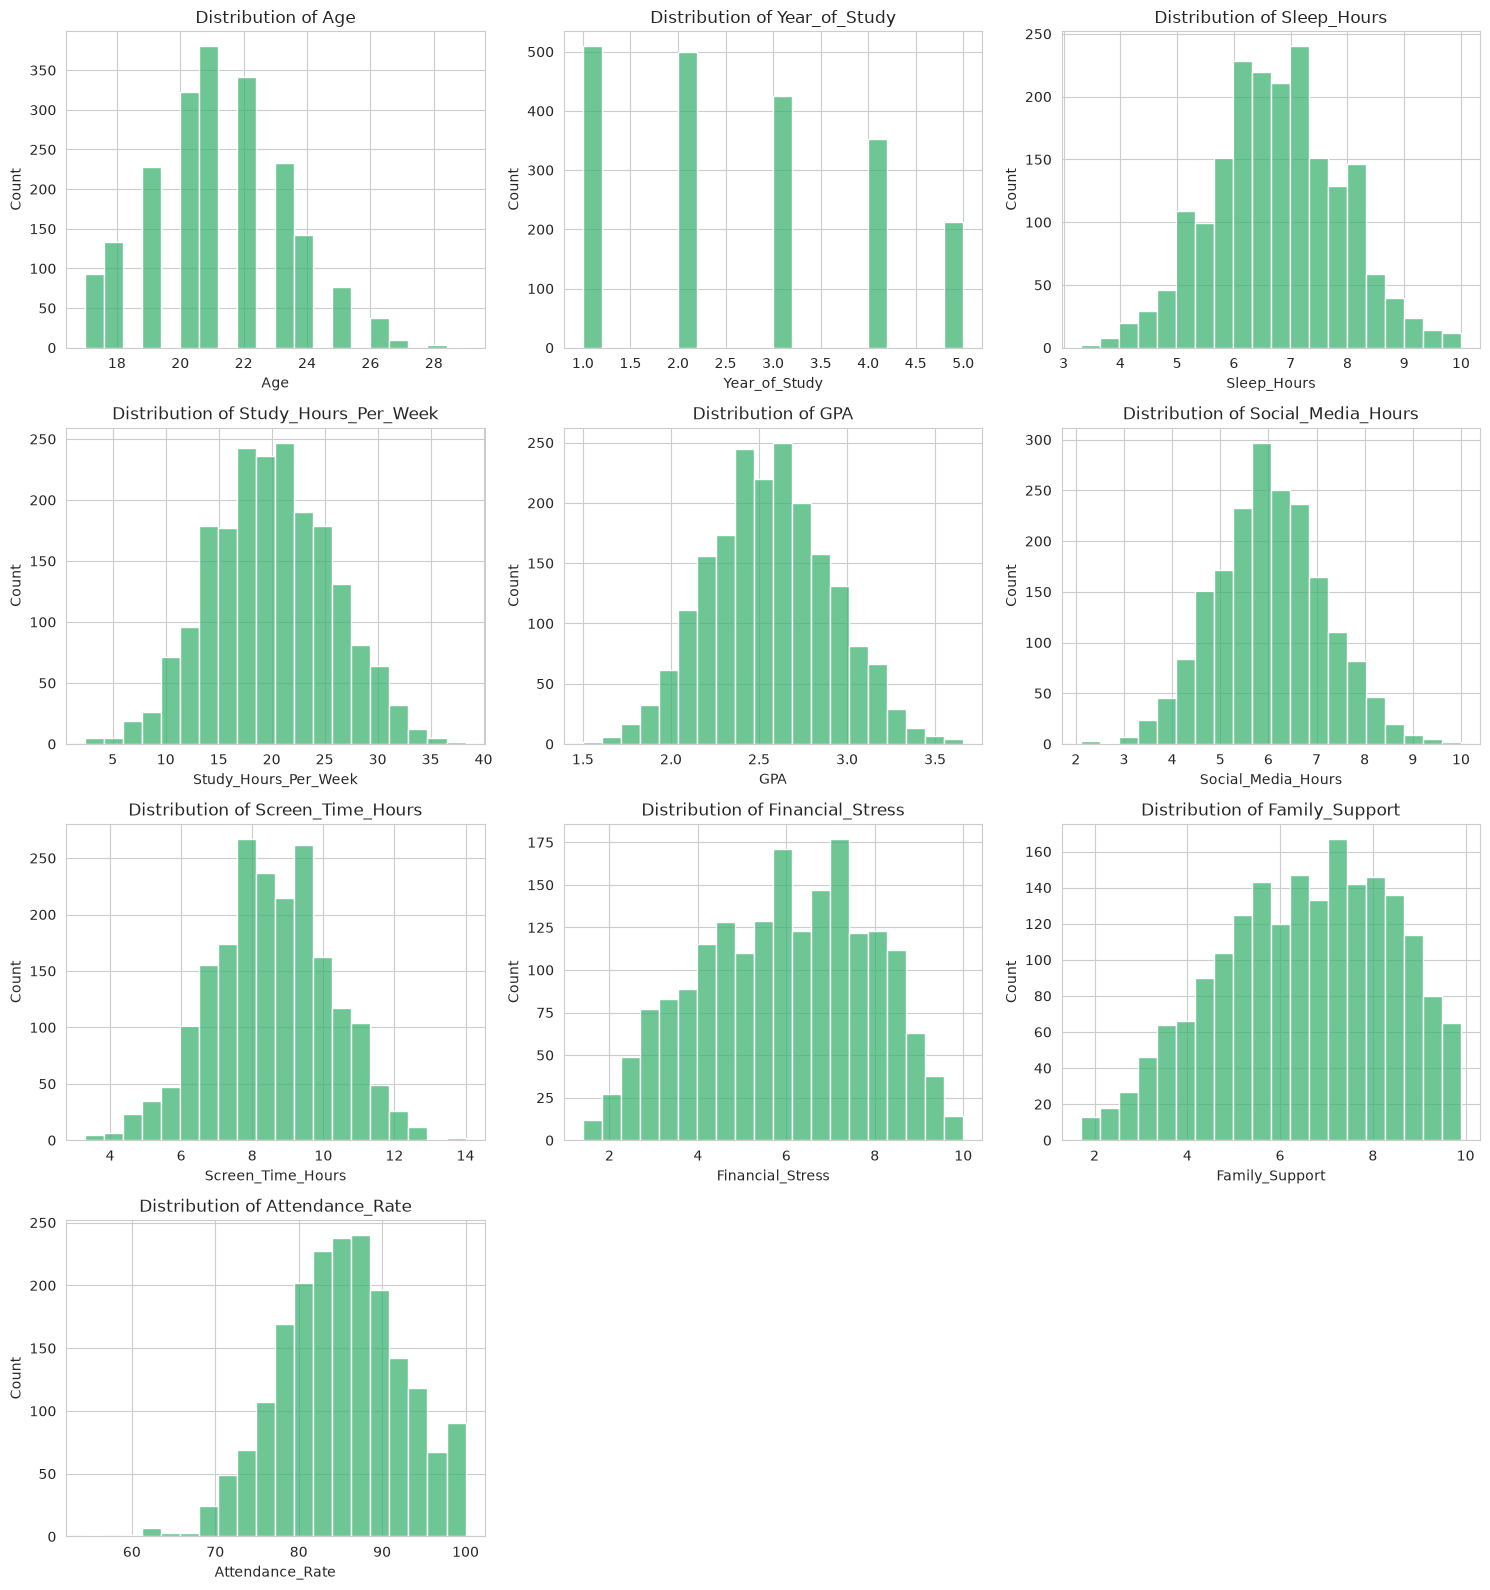

In [15]:
rows = (len(num_cols) + 2) // 3

plt.figure(figsize=(15, 4 * rows))
for i, col in enumerate(num_cols):
    plt.subplot(rows, 3, i + 1)
    sns.histplot(df[col], bins=20, color="mediumseagreen")
    plt.title("Distribution of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Distribution of the categorical features

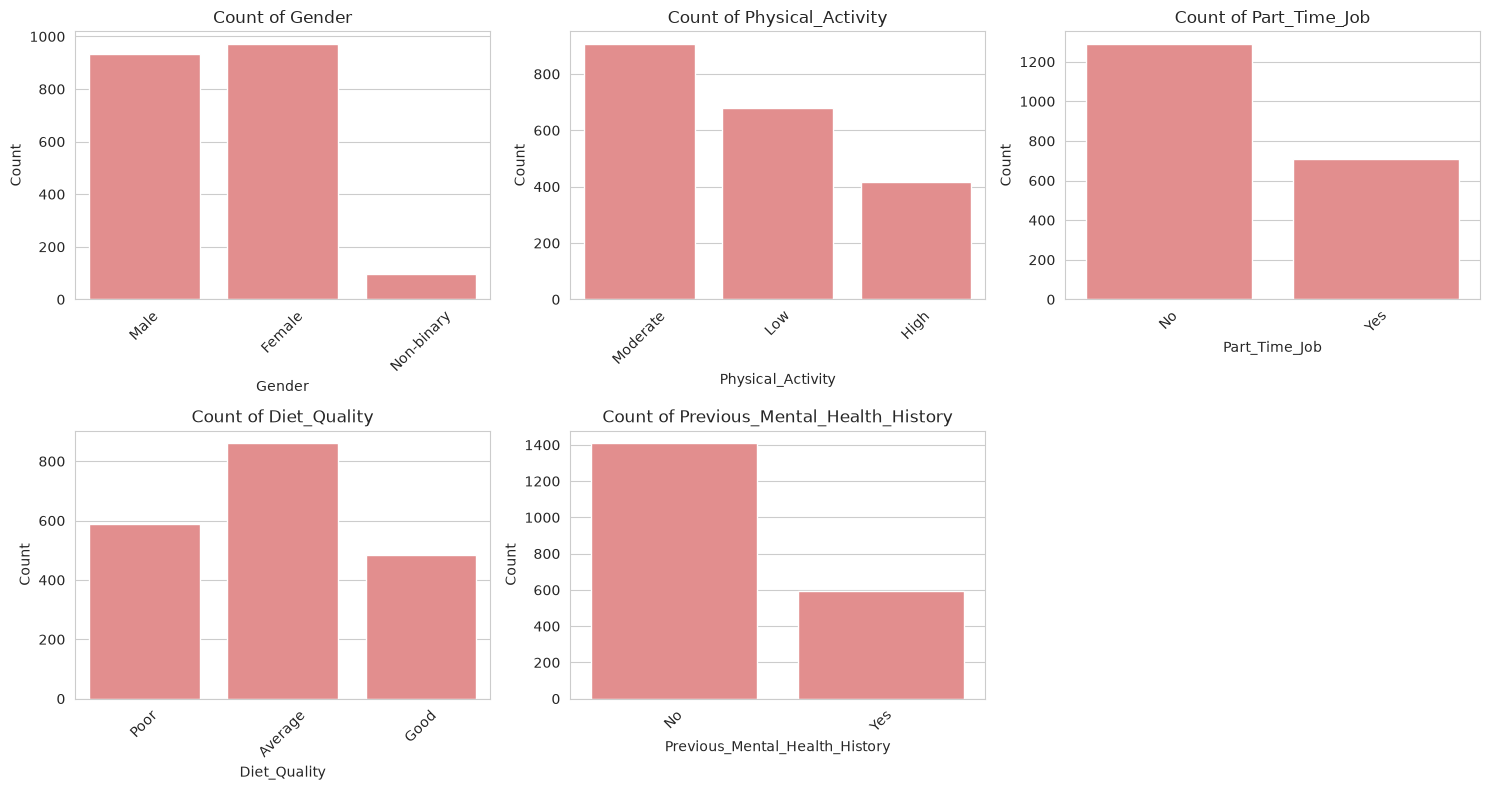

In [16]:
rows = (len(cat_cols) + 2) // 3

plt.figure(figsize=(15, 4 * rows))
for i, col in enumerate(cat_cols):
    plt.subplot(rows, 3, i + 1)
    sns.countplot(x=df[col], color="lightcoral")
    plt.title("Count of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Numerical features vs target

In [17]:
df.groupby(target)[num_cols].mean()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
Mental_Health_Risk,,,,,,,,,,
High,21.138235,2.360294,6.035258,18.362794,2.421604,6.345770,8.960000,6.689697,5.956212,83.767117
Low,21.112121,2.895455,7.523648,21.699697,2.718176,5.762773,8.257424,5.243930,7.088438,86.332293
Medium,21.143939,2.642424,6.729384,19.980758,2.552099,5.922414,8.415606,5.895024,6.527864,85.191641


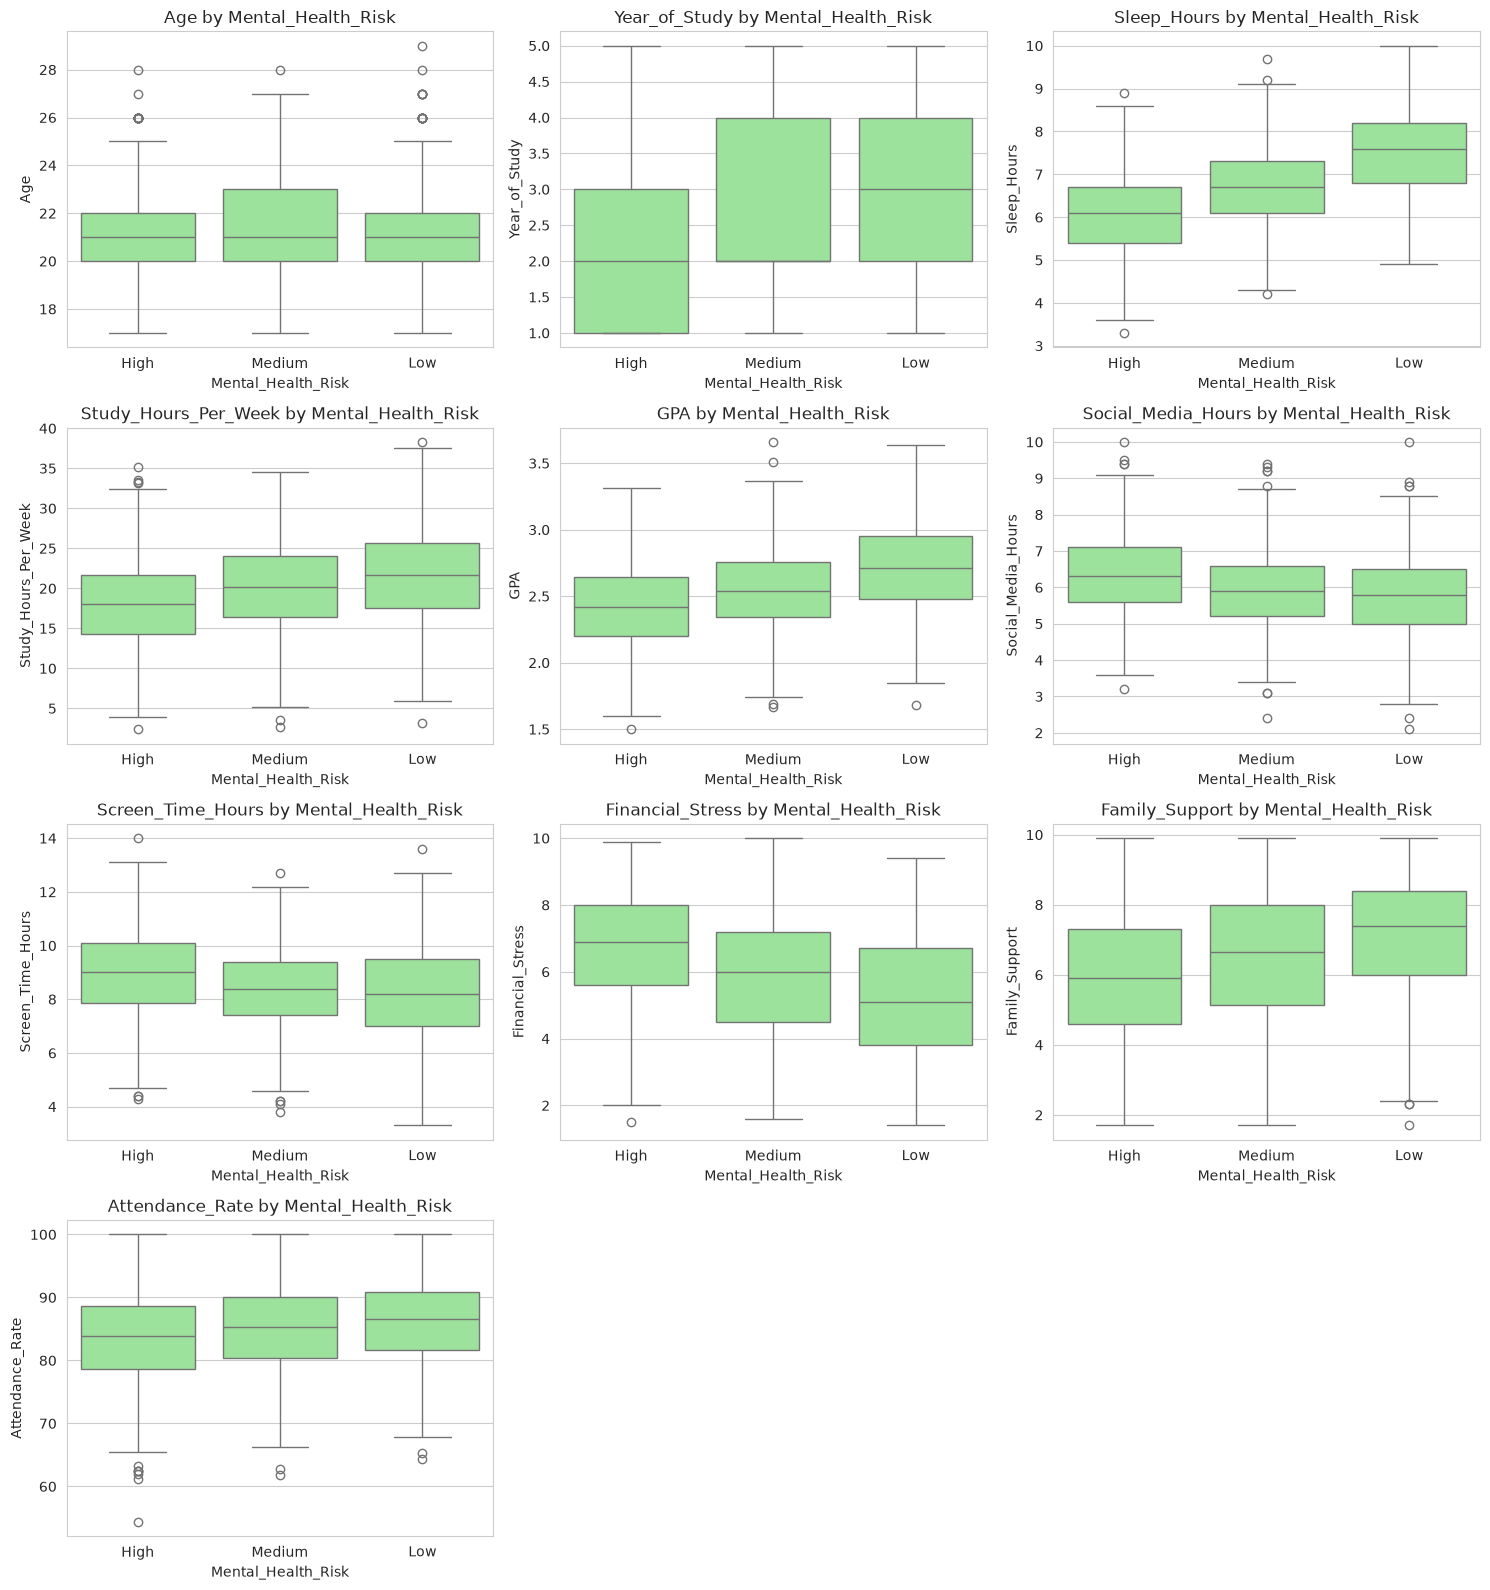

In [18]:
rows = (len(num_cols) + 2) // 3

plt.figure(figsize=(15, 4 * rows))
for i, col in enumerate(num_cols):
    plt.subplot(rows, 3, i + 1)
    sns.boxplot(x=df[target], y=df[col], color="lightgreen")
    plt.title(col + " by " + target)
    plt.xlabel(target)
    plt.ylabel(col)
plt.tight_layout()
plt.show()

## Categorical features vs target

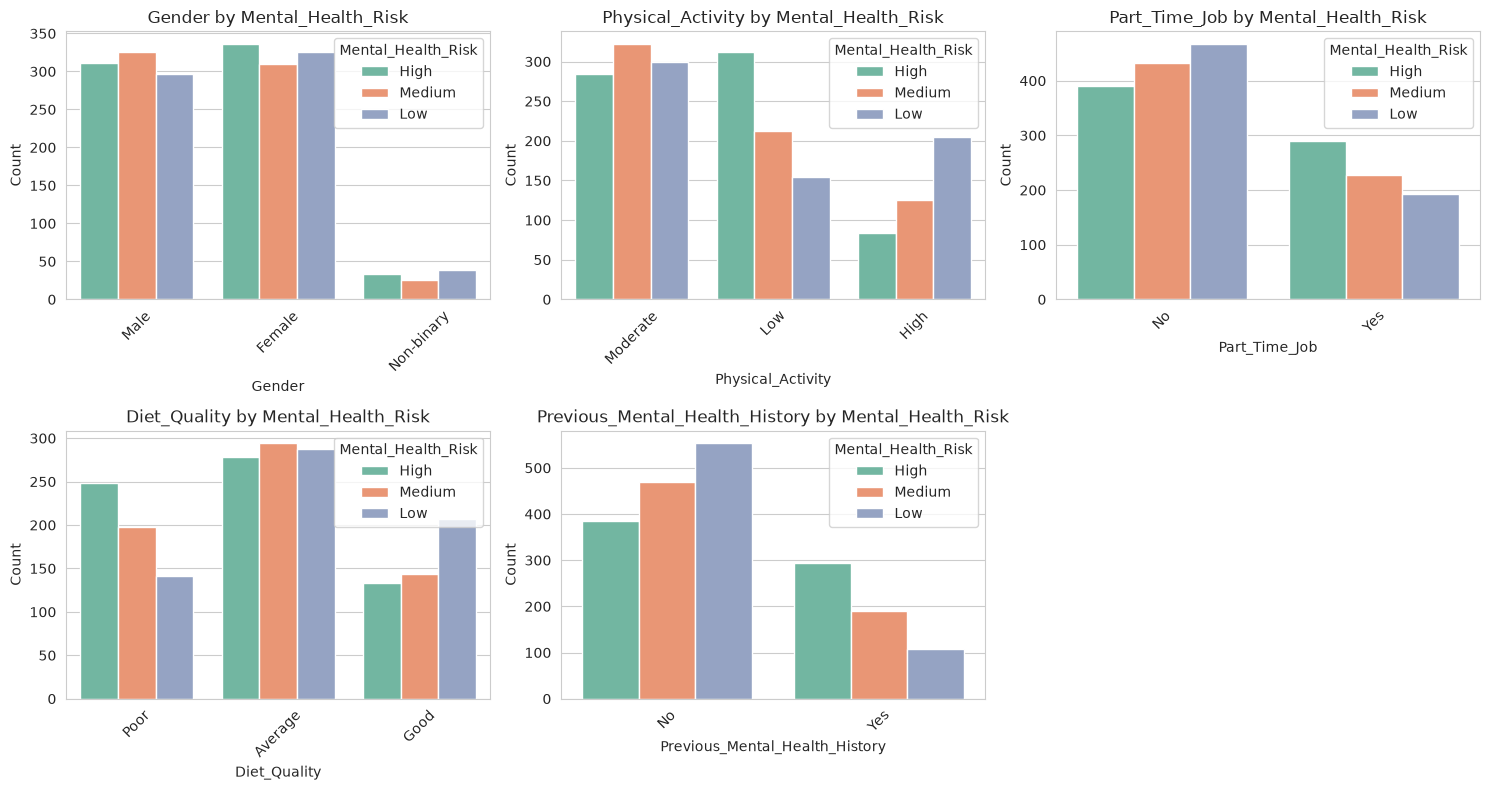

In [19]:
rows = (len(cat_cols) + 2) // 3

plt.figure(figsize=(15, 4 * rows))
for i, col in enumerate(cat_cols):
    plt.subplot(rows, 3, i + 1)
    sns.countplot(x=df[col], hue=df[target], palette="Set2")
    plt.title(col + " by " + target)
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
for col in cat_cols:
    print(pd.crosstab(df[col], df[target], normalize="index").round(2))
    print()

Mental_Health_Risk  High   Low  Medium
Gender                                
Female              0.35  0.33    0.32
Male                0.33  0.32    0.35
Non-binary          0.34  0.40    0.26

Mental_Health_Risk  High   Low  Medium
Physical_Activity                     
High                0.20  0.49    0.30
Low                 0.46  0.23    0.31
Moderate            0.31  0.33    0.36

Mental_Health_Risk  High   Low  Medium
Part_Time_Job                         
No                  0.30  0.36    0.34
Yes                 0.41  0.27    0.32

Mental_Health_Risk  High   Low  Medium
Diet_Quality                          
Average             0.32  0.33    0.34
Good                0.27  0.43    0.30
Poor                0.42  0.24    0.34

Mental_Health_Risk              High   Low  Medium
Previous_Mental_Health_History                    
No                              0.27  0.39    0.33
Yes                             0.50  0.18    0.32



## Correlation between numerical features

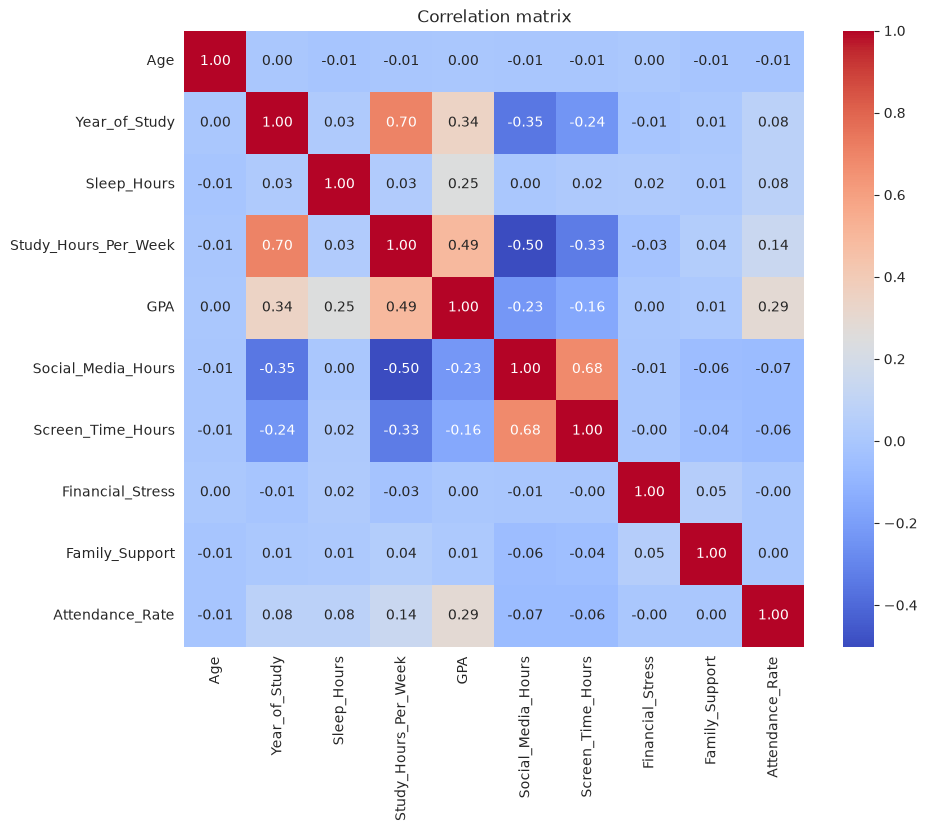

In [21]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()